<a href="https://colab.research.google.com/github/ayudewanti14/implementasi1/blob/main/implementasi1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
np.random.seed(42)

n = 5000

# Data customer dan produk
customer_id = np.random.randint(1, 121, n)
product_id = np.random.randint(1, 25, n)

# Tanggal invoice dalam rentang 2 tahun
invoice_date = (
    pd.Timestamp("2024-07-01")
    + pd.to_timedelta(
        np.random.randint(0, 730, n), unit="D"
    )
)

# Informasi invoice
amount = np.round(
    np.random.lognormal(mean=14, sigma=0.65, size=n), 0
).astype(int)

credit_limit = np.random.choice(
    [10_000_000, 25_000_000, 50_000_000, 100_000_000],
    size=n
)

payment_method = np.random.choice(
    ["Transfer", "Tunai", "Kredit"],
    size=n,
    p=[0.45, 0.20, 0.35]
)

customer_type = np.random.choice(
    ["Retail", "Grosir", "Corporate"],
    size=n,
    p=[0.40, 0.35, 0.25]
)

# Simulasi probabilitas terlambat bayar.
# Ini hanya aturan pembentuk data sintetis, bukan hasil perusahaan asli.
risk_score = (
    -2.1
    + 0.9 * (payment_method == "Kredit")
    + 0.7 * (customer_type == "Corporate")
    + 0.8 * (amount > credit_limit)
    + 0.6 * (invoice_date.month == 12)
)

prob_late = 1 / (1 + np.exp(-risk_score))
late_payment = np.random.binomial(1, prob_late)

# Lama keterlambatan hanya untuk deskripsi hasil simulasi
days_late = np.where(
    late_payment == 1,
    np.random.randint(31, 91, n),
    np.random.randint(0, 31, n)
)

df = pd.DataFrame({
    "invoice_id": [f"INV-{i:05d}" for i in range(1, n + 1)],
    "customer_id": customer_id,
    "product_id": product_id,
    "invoice_date": invoice_date,
    "amount": amount,
    "credit_limit": credit_limit,
    "payment_method": payment_method,
    "customer_type": customer_type,
    "days_late": days_late,
    "late_payment": late_payment
})

# Target 1 berarti terlambat lebih dari 30 hari.
df["late_payment"] = (df["days_late"] > 30).astype(int)

display(df.head())
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah customer:", df["customer_id"].nunique())
print("Jumlah produk:", df["product_id"].nunique())

,invoice_id,customer_id,product_id,invoice_date,amount,credit_limit,payment_method,customer_type,days_late,late_payment
0,INV-00001,103,6,2025-05-28,2860789,25000000,Kredit,Grosir,27,0
1,INV-00002,52,12,2026-06-17,701989,100000000,Kredit,Retail,4,0
2,INV-00003,93,12,2026-01-02,753647,10000000,Transfer,Retail,2,0
3,INV-00004,15,21,2026-02-21,755814,50000000,Kredit,Corporate,79,1
4,INV-00005,107,8,2025-03-13,1250108,25000000,Transfer,Grosir,65,1


Jumlah baris dan kolom: (5000, 10)
Jumlah customer: 120
Jumlah produk: 24


In [3]:
print("Informasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

print("\nMissing value per kolom:")
display(df.isnull().sum().to_frame("missing_value"))

print("\nJumlah baris duplikat:", df.duplicated().sum())

print("\nDistribusi target:")
display(
    df["late_payment"]
    .value_counts()
    .rename(index={0: "Tidak terlambat", 1: "Terlambat"})
    .to_frame("jumlah")
)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   invoice_id      5000 non-null   object        
 1   customer_id     5000 non-null   int64         
 2   product_id      5000 non-null   int64         
 3   invoice_date    5000 non-null   datetime64[ns]
 4   amount          5000 non-null   int64         
 5   credit_limit    5000 non-null   int64         
 6   payment_method  5000 non-null   object        
 7   customer_type   5000 non-null   object        
 8   days_late       5000 non-null   int64         
 9   late_payment    5000 non-null   int64         
dtypes: datetime64[ns](1), int64(6), object(3)
memory usage: 390.8+ KB

Statistik deskriptif:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
invoice_id,5000,5000,INV-05000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,5000.0,NaN,NaN,NaN,59.6224,1.0,29.0,59.0,90.0,120.0,34.975335
product_id,5000.0,NaN,NaN,NaN,12.723,1.0,7.0,13.0,19.0,24.0,6.915247
invoice_date,5000,NaN,NaN,NaN,2025-07-04 18:11:13.919999744,2024-07-01 00:00:00,2025-01-03 00:00:00,2025-07-08 00:00:00,2026-01-06 06:00:00,2026-06-30 00:00:00,NaN
amount,5000.0,NaN,NaN,NaN,1480734.6454,129733.0,773139.75,1199203.5,1871849.25,11096030.0,1061190.893448
credit_limit,5000.0,NaN,NaN,NaN,46534000.0,10000000.0,25000000.0,25000000.0,100000000.0,100000000.0,34401504.861084
payment_method,5000,3,Transfer,2282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_type,5000,3,Retail,1956,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_late,5000.0,NaN,NaN,NaN,23.4454,0.0,9.0,19.0,28.0,90.0,21.101537
late_payment,5000.0,NaN,NaN,NaN,0.187,0.0,0.0,0.0,0.0,1.0,0.389951



Missing value per kolom:


,missing_value
invoice_id,0
customer_id,0
product_id,0
invoice_date,0
amount,0
credit_limit,0
payment_method,0
customer_type,0
days_late,0
late_payment,0



Jumlah baris duplikat: 0

Distribusi target:


,jumlah
late_payment,
Tidak terlambat,4065
Terlambat,935


In [4]:
np.random.seed(10)

months = pd.date_range(
    start="2024-07-01",
    periods=24,
    freq="MS"
)

sales = np.linspace(180_000_000, 260_000_000, 24)
sales += np.random.normal(0, 12_000_000, 24)

operating_expense = np.linspace(65_000_000, 100_000_000, 24)
operating_expense += np.random.normal(0, 6_000_000, 24)

net_profit = sales * 0.16 - operating_expense * 0.25
net_profit += np.random.normal(0, 4_000_000, 24)

receivables = np.linspace(40_000_000, 150_000_000, 24)
receivables += np.random.normal(0, 8_000_000, 24)

operating_cash_flow = net_profit - np.diff(
    np.r_[receivables[0], receivables]
)

finance = pd.DataFrame({
    "month": months,
    "sales_revenue": sales.round(0),
    "operating_expense": operating_expense.round(0),
    "net_profit": net_profit.round(0),
    "receivables": receivables.round(0),
    "operating_cash_flow": operating_cash_flow.round(0)
})

finance["gross_margin_rate"] = (
    (finance["sales_revenue"] - finance["operating_expense"])
    / finance["sales_revenue"] * 100
).round(2)

display(finance.head())

,month,sales_revenue,operating_expense,net_profit,receivables,operating_cash_flow,gross_margin_rate
0,2024-07-01,195979038.0,71742148.0,15681720.0,38273681.0,15681720.0,63.39
1,2024-08-01,192061609.0,76557472.0,11000808.0,52695188.0,-3420699.0,60.14
2,2024-09-01,168411718.0,68638374.0,9682660.0,52083248.0,10294601.0,59.24
3,2024-10-01,190334176.0,77953196.0,12121546.0,74089035.0,-9884241.0,59.04
4,2024-11-01,201369075.0,69459469.0,12694669.0,47063863.0,39719840.0,65.51


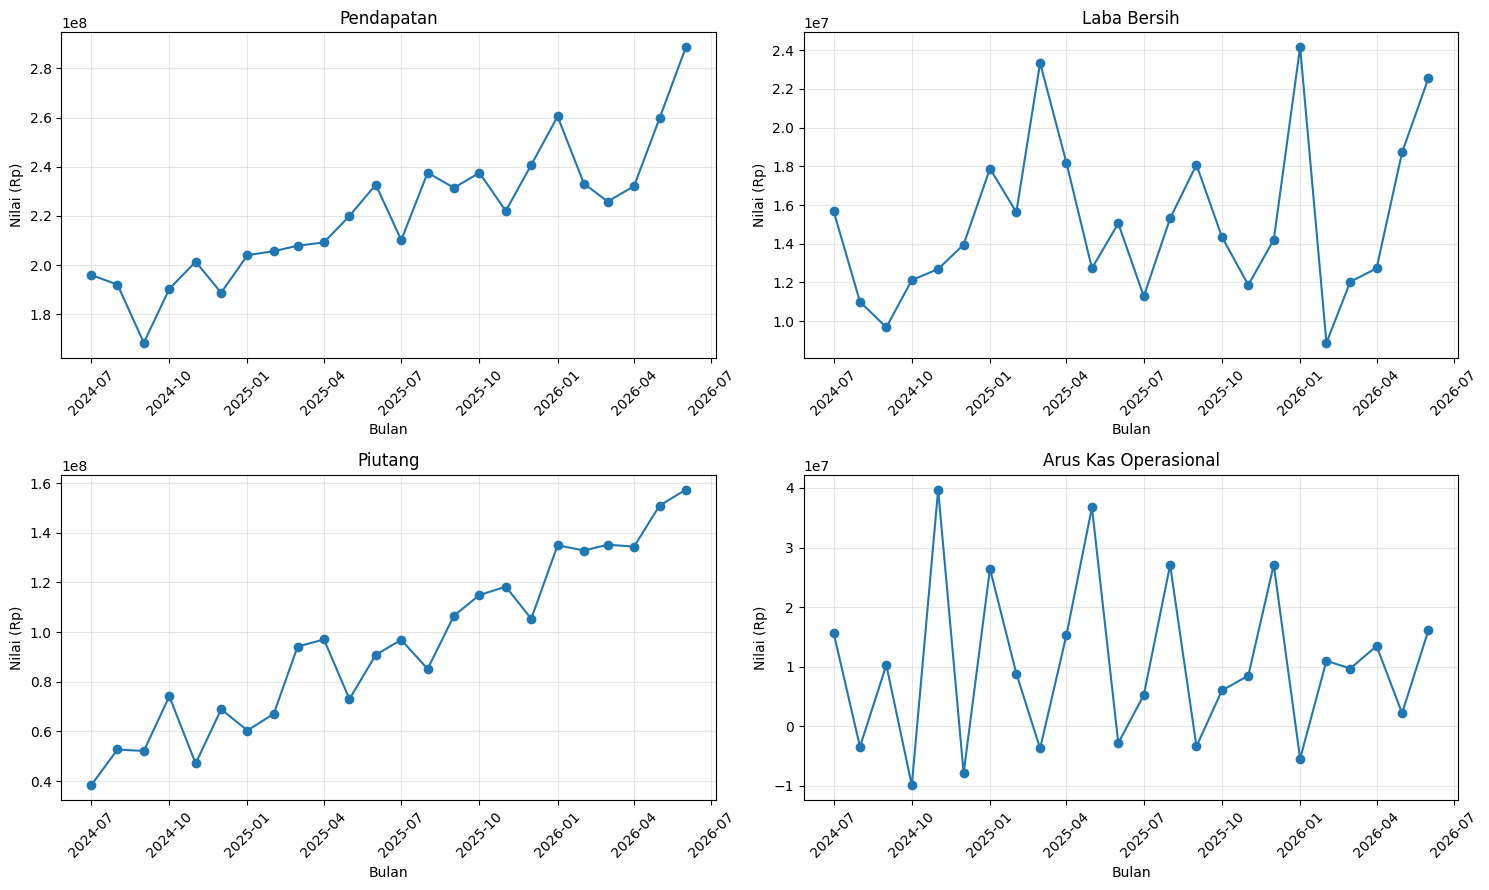

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

metrics = [
    ("sales_revenue", "Pendapatan"),
    ("net_profit", "Laba Bersih"),
    ("receivables", "Piutang"),
    ("operating_cash_flow", "Arus Kas Operasional")
]

for ax, (column, title) in zip(axes.flatten(), metrics):
    ax.plot(
        finance["month"],
        finance[column],
        marker="o"
    )
    ax.set_title(title)
    ax.set_xlabel("Bulan")
    ax.set_ylabel("Nilai (Rp)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
finance["period"] = np.where(
    finance["month"] < finance["month"].iloc[12],
    "12 Bulan Pertama",
    "12 Bulan Terakhir"
)

summary = finance.groupby("period").agg(
    total_revenue=("sales_revenue", "sum"),
    total_operating_expense=("operating_expense", "sum"),
    total_net_profit=("net_profit", "sum"),
    average_receivables=("receivables", "mean"),
    total_operating_cash_flow=("operating_cash_flow", "sum"),
    average_gross_margin_rate=("gross_margin_rate", "mean")
).round(2)

display(summary.T)

period,12 Bulan Pertama,12 Bulan Terakhir
total_revenue,2.416375e+09,2.879277e+09
total_operating_expense,9.103078e+08,1.090106e+09
total_net_profit,1.779739e+08,1.841984e+08
average_receivables,6.795486e+07,1.227200e+08
total_operating_cash_flow,1.254211e+08,1.176788e+08
average_gross_margin_rate,6.223000e+01,6.198000e+01


In [7]:
# Ekstraksi bulan dari tanggal invoice
df["invoice_month"] = df["invoice_date"].dt.month

# Fitur yang tersedia ketika invoice diterbitkan
features = [
    "customer_id",
    "product_id",
    "invoice_month",
    "amount",
    "credit_limit",
    "payment_method",
    "customer_type"
]

target = "late_payment"

X = df[features].copy()
y = df[target].copy()

categorical_features = [
    "customer_id",
    "product_id",
    "payment_method",
    "customer_type"
]

numeric_features = [
    "invoice_month",
    "amount",
    "credit_limit"
]

# Preprocessing untuk data numerik
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing untuk data kategorikal
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Fitur:", features)
print("\nJumlah target:")
print(y.value_counts())

Fitur: ['customer_id', 'product_id', 'invoice_month', 'amount', 'credit_limit', 'payment_method', 'customer_type']

Jumlah target:
late_payment
0    4065
1     935
Name: count, dtype: int64


In [8]:
data = df.sort_values("invoice_date").reset_index(drop=True)

split_idx = int(len(data) * 0.8)

train_data = data.iloc[:split_idx]
test_data = data.iloc[split_idx:]

X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nProporsi kelas training:")
print(y_train.value_counts(normalize=True).round(3))

print("\nProporsi kelas testing:")
print(y_test.value_counts(normalize=True).round(3))

Jumlah data training: 4000
Jumlah data testing: 1000

Proporsi kelas training:
late_payment
0    0.814
1    0.186
Name: proportion, dtype: float64

Proporsi kelas testing:
late_payment
0    0.808
1    0.192
Name: proportion, dtype: float64


In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "Recall", ascending=False
)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
1,Decision Tree,0.568,0.260,0.677,0.376
0,Logistic Regression,0.625,0.272,0.568,0.368
2,Random Forest,0.683,0.302,0.495,0.375


Model dengan recall tertinggi: Decision Tree

                 precision    recall  f1-score   support

Tidak terlambat       0.88      0.54      0.67       808
      Terlambat       0.26      0.68      0.38       192

       accuracy                           0.57      1000
      macro avg       0.57      0.61      0.52      1000
   weighted avg       0.76      0.57      0.61      1000



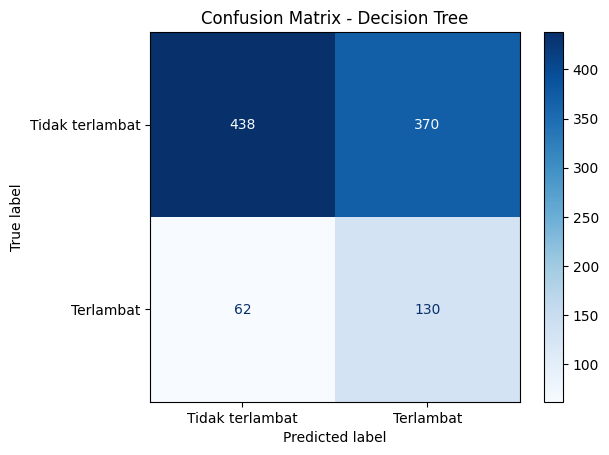

In [10]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

best_predictions = best_model.predict(X_test)

print("Model dengan recall tertinggi:", best_name)
print()
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["Tidak terlambat", "Terlambat"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=[0, 1],
    display_labels=["Tidak terlambat", "Terlambat"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_name}")
plt.show()

,Fitur,Importance
147,cat__payment_method_Kredit,0.125750
1,num__amount,0.097947
150,cat__customer_type_Corporate,0.074730
0,num__invoice_month,0.063210
148,cat__payment_method_Transfer,0.062449
2,num__credit_limit,0.035577
149,cat__payment_method_Tunai,0.029502
152,cat__customer_type_Retail,0.028202
151,cat__customer_type_Grosir,0.025681
135,cat__product_id_13,0.009294


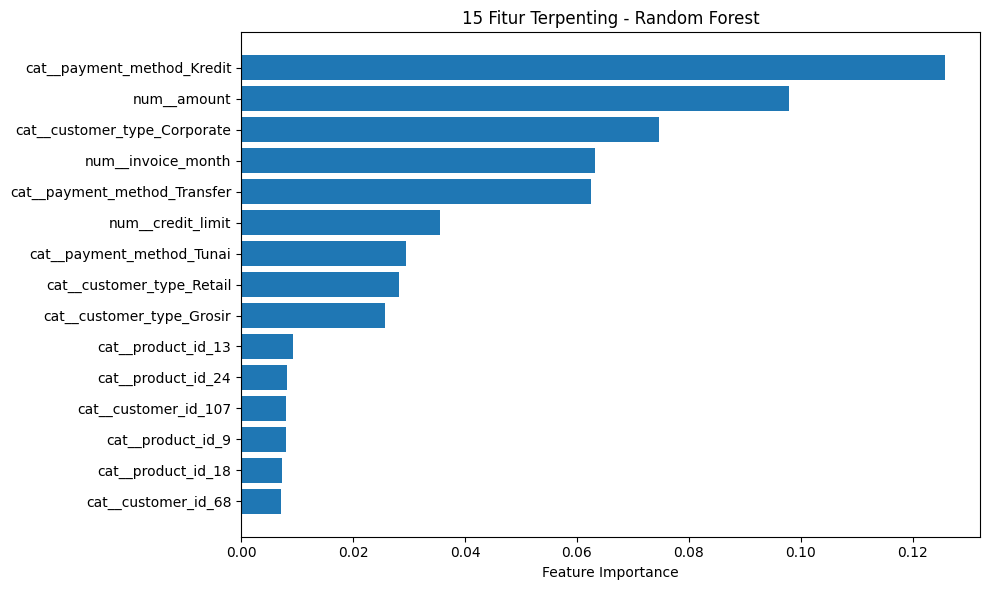

In [11]:
rf_pipeline = trained_models["Random Forest"]

rf_model = rf_pipeline.named_steps["model"]
preprocessor_fitted = rf_pipeline.named_steps["preprocessing"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance_df = pd.DataFrame({
    "Fitur": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Fitur"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("15 Fitur Terpenting - Random Forest")
plt.tight_layout()
plt.show()

In [12]:
invoice_baru = pd.DataFrame([{
    "customer_id": 15,
    "product_id": 7,
    "invoice_month": 12,
    "amount": 80_000_000,
    "credit_limit": 50_000_000,
    "payment_method": "Kredit",
    "customer_type": "Corporate"
}])

probabilities = best_model.predict_proba(invoice_baru[features])[0]
classes = list(best_model.named_steps["model"].classes_)

late_probability = probabilities[classes.index(1)]
prediction = best_model.predict(invoice_baru[features])[0]

print("Probabilitas terlambat:", f"{late_probability:.2%}")
print(
    "Prediksi:",
    "Berpotensi terlambat" if prediction == 1
    else "Tidak terindikasi terlambat"
)

Probabilitas terlambat: 78.41%
Prediksi: Berpotensi terlambat
